# In-class Competition: Improved Model Tutorial
This NOTEBOOK follows the same steps as `tutorial.ipynb`, but goes further: it uses **all the features**, creates **new features**, trains **gradient-boosting models** (LightGBM and CatBoost), tunes them, and **blends** them into the final prediction.

First, let's review the task we will be performing (see README.ipynb for details).

**Objective**: To predict the probability of default based on customer data.

**Evaluation metric**: ROC-AUC (Area Under the Receiver Operating Characteristic Curve)

**What changes compared with `tutorial.ipynb`?**

| | `tutorial.ipynb` | This notebook |
|---|---|---|
| Features | 5 of 32 | all 32 + 10 new features (a 112-feature version is used by one model) |
| Missing values | filled with the mean | kept as missing (the models can use them) |
| Text columns | label / count / one-hot encoding | handled natively by the models |
| Models | Logistic regression, Random forest | LightGBM, CatBoost (gradient boosting) |
| Evaluation | one 70/30 holdout split | 5-fold cross-validation, several seeds |
| Hyperparameters | defaults | tuned with Optuna |
| Final prediction | one model | average of 3 models |

**Result.** The out-of-fold ROC-AUC of the final blend is about **0.764** (printed in Section 5.9). A previous run of this same approach scored **0.7664** on the public leaderboard. An AUC close to 1 is not realistic for this data: whether a customer repays depends on future events that are not in the table, so a score around 0.76 to 0.78 is a strong result.

## Contents
- 1.Setup
- 2.Loading the Data
- 3.Visualizing and Understanding the Data
- 4.Preprocessing and Feature Creation
- 5.Building the Machine Learning Model
- 6.Creating prediction results

## 1.Setup

### 1.1 Import Libraries
Let's load basic libraries.
Other required libraries will be loaded when we explain them.
- numpy: Library for efficient numerical computation
- pandas: Library useful for data analysis
- matplotlib: Graph drawing library
- seaborn: Graph drawing library as well

In [ ]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

### 1.2 Connect with Google Drive
To load the data, we first need to connect this Colab notebook with Google Drive.
(If you run the notebook on your own computer, this step is skipped automatically.)

In [ ]:
# If you work with Google Colaboratory, please run this as well.
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Not running in Google Colab, so there is nothing to connect.")

Mounted at /content/drive


Next, we need to navigate to where the `competition` folder is located

**IMPORTANT**:<br>
Change `WORKDIR` below to match the folder where this notebook is saved on Google Drive by **replacing "WhereThisNotebookIsLocated" with your actual folder path**.

Examples:
- You uploaded `competition` folder directly under MyDrive (the default folder when you open Google Drive)
    - Change to "/content/drive/MyDrive/competition"
- You uploaded `competition` folder inside a folder named `00_GCIGlobal` under MyDrive
    - Change to "/content/drive/MyDrive/00_GCIGlobal/competition"

If you run the notebook on your own computer from inside the `competition` folder, you do not need to change anything.

In [ ]:
import os

# Specify the directory where this notebook is located.
WORKDIR = "/content/drive/MyDrive/Competition"
if os.path.isdir(WORKDIR):
    os.chdir(WORKDIR)
print("Current directory:", os.getcwd())

Current directory: /content/drive/MyDrive/Competition


Run the cell below to check if the path is correctly set.

In [ ]:
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


## 2.Loading the Data

### 2.1 Data Overview
Run the cell to load the dataset as `pd.DataFrame`.

**IMPORTANT:**<br>
**When you make modifications to preprocessing or model training, always make sure to run all cells from this cell.**

In [ ]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

Before conducting a full-scale analysis, we will first review a brief overview of the data.

In [ ]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [ ]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0


Excluding the `TARGET` column in train data and the `SK_ID_CURR` which represents ID number, you can see that there are 32 types of features.

### 2.2 Selecting Features

The original tutorial starts with 5 features and suggests adding more one by one. Here we take the next step: **we use all 32 features** and let the model decide which ones matter. (Gradient-boosting models handle many features well, and they largely ignore the useless ones.)

We only drop `SK_ID_CURR`. It is just an identifier, so it carries no real information. We keep the IDs of the test rows aside, because we need them to build the submission file later.

In [ ]:
# Use all 32 features (everything except the ID and the target)
use_features = [c for c in train.columns if c not in ("SK_ID_CURR", "TARGET")]
target = train["TARGET"].values
test_ids = test["SK_ID_CURR"].values   # keep for the submission file

train = train[use_features]
train["TARGET"] = target
test = test[use_features]
print("number of features:", len(use_features))

number of features: 32


In [ ]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 33)


,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,Married,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,Married,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,Married,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [ ]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 32)


,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,Married,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,Married,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,Single / not married,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0


### **[Next Steps]**
> + Check `HomeCredit_columns_description.xlsx` to understand what each column represents. Knowing what a column means is how you come up with good new features.
> + When you change which features to use, always restart from [Section 2.1](#) by reloading the dataset.

## 3.Visualizing and Understanding the Data

The first thing we need to do before building the machine learning model is to **understand the data**. We do this by visualizing and analyzing, to deepen our understanding of data distribution, missing values, outliers, correlations, and etc. The results of the analysis obtained at this stage will be useful for preprocessing, feature creation, and selection of machine learning models, which are all important to building models with better prediction ability.

### 3.1 Checking missing values
In this section, we check for missing values.
Many machine learning models cannot be trained on data with missing values, so they have to be filled. Some models, such as LightGBM and CatBoost (which we use later), can work with missing values directly. We will see why that matters in Section 4.

In [ ]:
# Check missing values of train data (only the columns that have any)
miss_train = train.isnull().sum()
miss_train[miss_train > 0]

,0
OWN_CAR_AGE,112992
CNT_FAM_MEMBERS,2
EXT_SOURCE_1,118928
EXT_SOURCE_2,369
EXT_SOURCE_3,54586
AMT_REQ_CREDIT_BUREAU_HOUR,23116
AMT_REQ_CREDIT_BUREAU_MON,23116
AMT_REQ_CREDIT_BUREAU_QRT,23116
AMT_REQ_CREDIT_BUREAU_YEAR,23116


In [ ]:
# Check missing values of test data (only the columns that have any)
miss_test = test.isnull().sum()
miss_test[miss_test > 0]

,0
OWN_CAR_AGE,40909
EXT_SOURCE_1,42912
EXT_SOURCE_2,130
EXT_SOURCE_3,19690
AMT_REQ_CREDIT_BUREAU_HOUR,8513
AMT_REQ_CREDIT_BUREAU_MON,8513
AMT_REQ_CREDIT_BUREAU_QRT,8513
AMT_REQ_CREDIT_BUREAU_YEAR,8513


In [ ]:
# Share of missing values in train (%)
(train.drop(columns="TARGET").isnull().mean() * 100).round(1).loc[lambda s: s > 0].sort_values(ascending=False)

,0
EXT_SOURCE_1,69.5
OWN_CAR_AGE,66.0
EXT_SOURCE_3,31.9
AMT_REQ_CREDIT_BUREAU_HOUR,13.5
AMT_REQ_CREDIT_BUREAU_QRT,13.5
AMT_REQ_CREDIT_BUREAU_MON,13.5
AMT_REQ_CREDIT_BUREAU_YEAR,13.5
EXT_SOURCE_2,0.2


We found that there are missing values in `OWN_CAR_AGE`, `EXT_SOURCE_1/2/3` and `AMT_REQ_CREDIT_BUREAU_*`. `EXT_SOURCE_1` is missing for about 70% of the customers and `OWN_CAR_AGE` for about 66%. Train and test have the same pattern.

**Findings**:<br>
* Need to decide how to deal with missing values in `OWN_CAR_AGE`, `EXT_SOURCE_*` and `AMT_REQ_CREDIT_BUREAU_*`

### 3.2 Visualization and analysis of each feature
In this section, we visualize each feature and analyze to see what kind of characteristics it has.

#### TARGET column

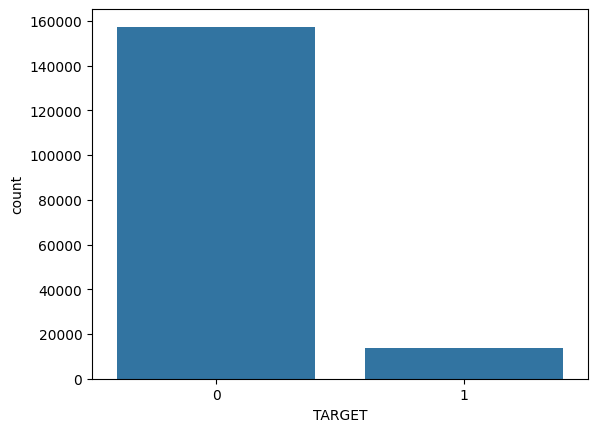

Default rate: 8.07%


In [ ]:
# The distribution of the target (default or not)
sns.countplot(data=train, x="TARGET")
plt.show()
print(f"Default rate: {train['TARGET'].mean():.2%}")

We can see that the **distribution of the objective variable is highly skewed**: only about 8% of the customers default. Data in which the distribution of the objective variable is highly skewed in this way is called **unbalanced data**.

When dealing with unbalanced data, we need to be particularly careful in selecting evaluation metrics. For example, if you choose accuracy, you will find that simply predicting all zeros will result in about 92% accuracy while catching no defaulter at all. This is why the competition uses **ROC-AUC**, which looks at how well the customers are *ranked* and does not depend on the class ratio.

Another approach to dealing with unbalanced data is to balance the target by undersampling or oversampling. We tested the model-side version of this (class weights) and it made the score slightly worse, so we do not use it. Details are in the Next Steps of Section 5.

**Findings**:<br>
* Use ROC-AUC (not accuracy) to judge models
* Use stratified splits so that every split keeps the same share of defaults

#### NAME_CONTRACT_TYPE column

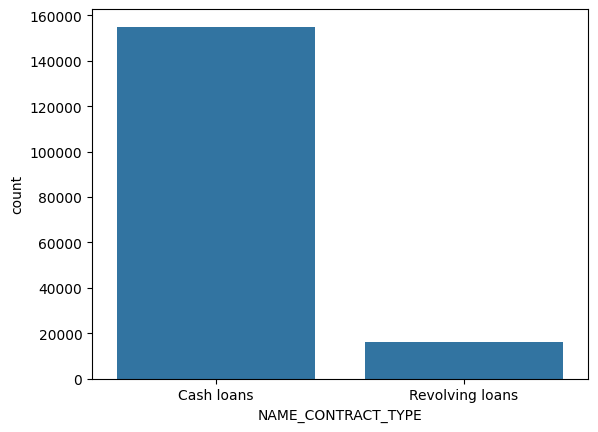

In [ ]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.show()

There are two variables in `NAME_CONTRACT_TYPE`, Cash loans and Revolving loans, but they are not evenly distributed. This is a text column, so the model needs a way to read it. We will handle it in Section 4.

**Findings**:<br>
* Text columns need to be converted or handled natively by the model

#### ORGANIZATION_TYPE column

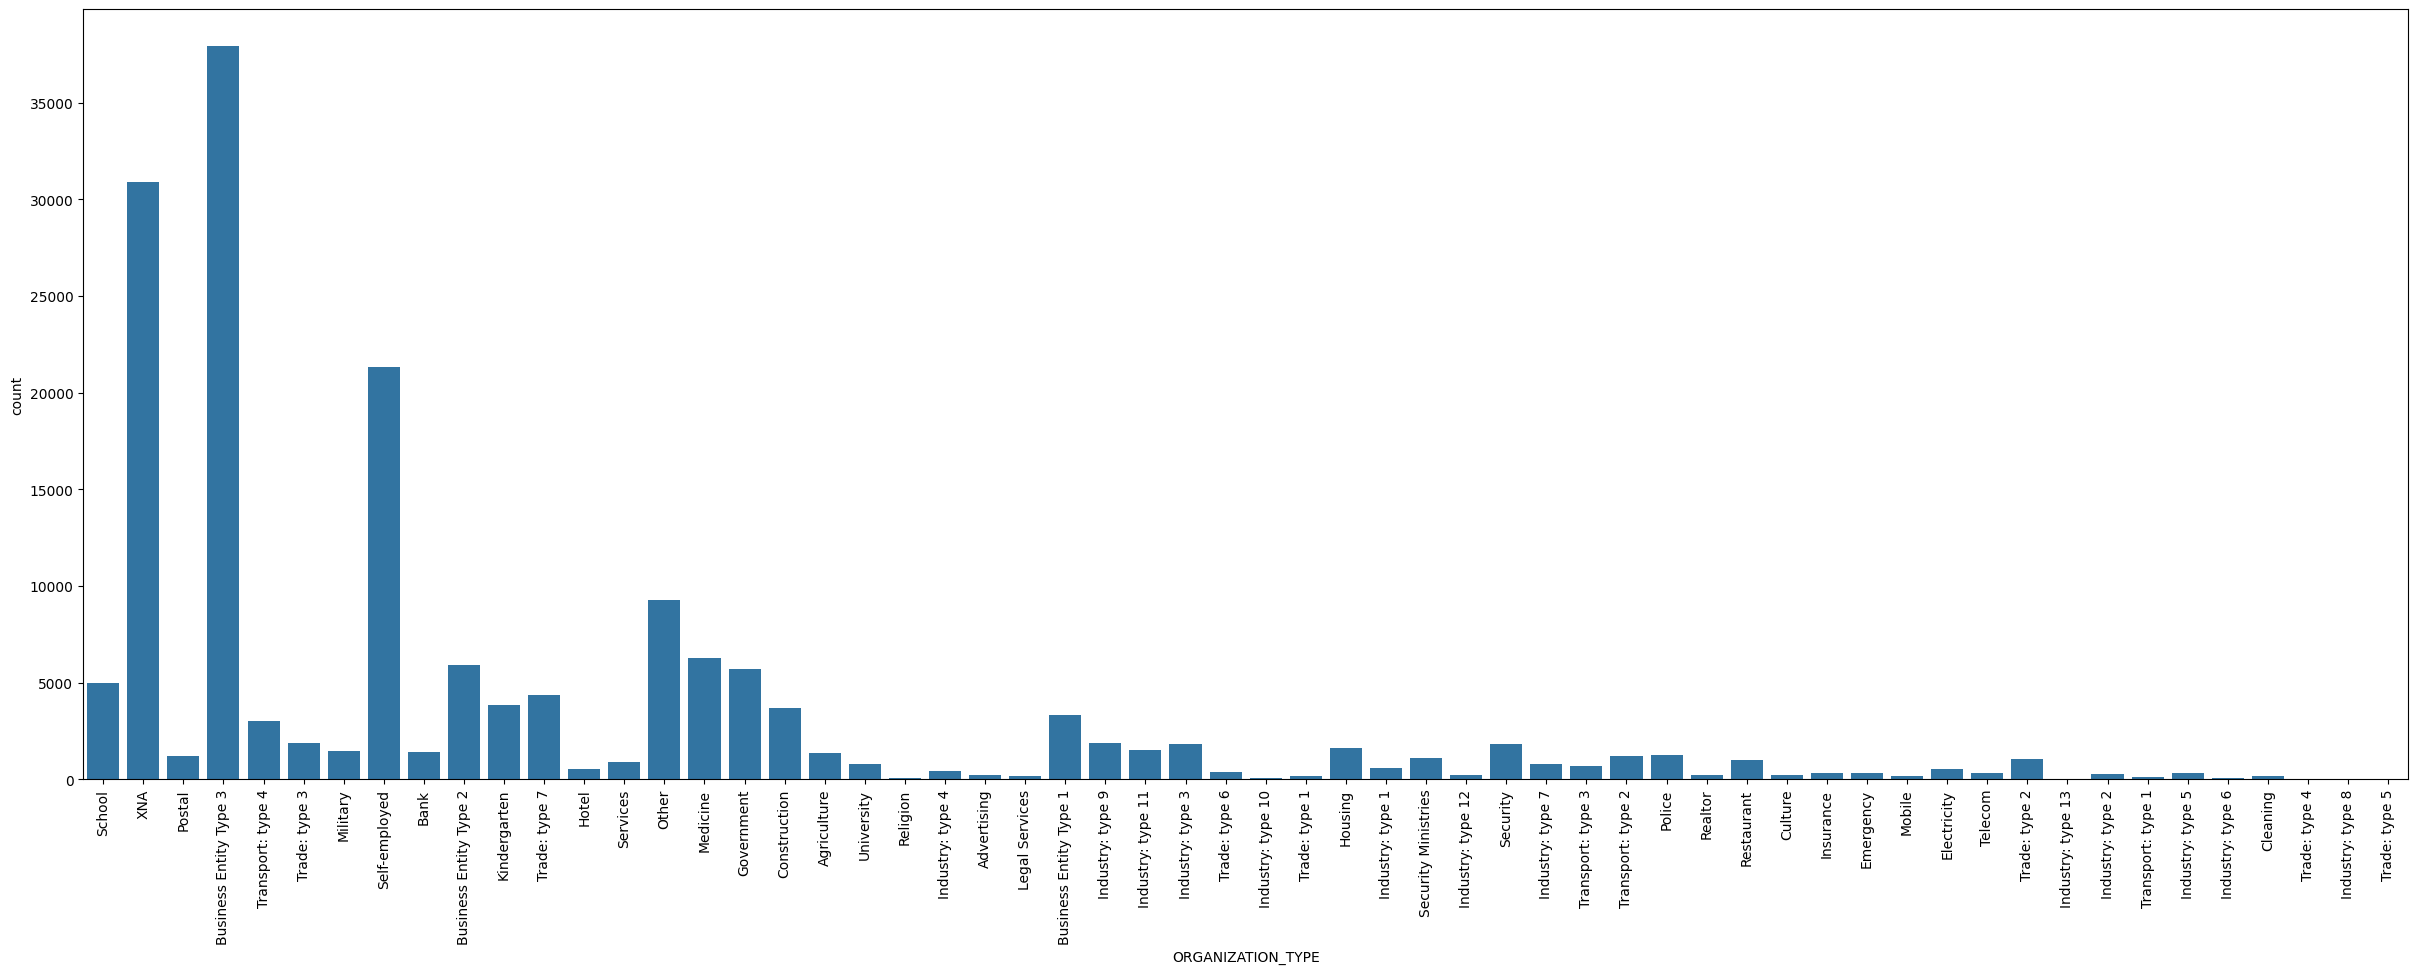

In [ ]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

There are many different `ORGANIZATION_TYPE`s (58), and you can also see that there is an ununiformity in the number of data. Also, the second variable from the left is "XNA", which we can infer from its name to be a missing value. About 30,000 customers have it.

**Findings**:<br>
* Treat "XNA" as missing values

#### CODE_GENDER column

In [ ]:
# The values of CODE_GENDER
train["CODE_GENDER"].value_counts()

,count
CODE_GENDER,
F,112549
M,58649
XNA,4


`CODE_GENDER` also has an "XNA" value, but only for 4 customers. We treat it as missing as well, for consistency.

**Findings**:<br>
* Treat "XNA" in `CODE_GENDER` as missing values

#### EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3 columns

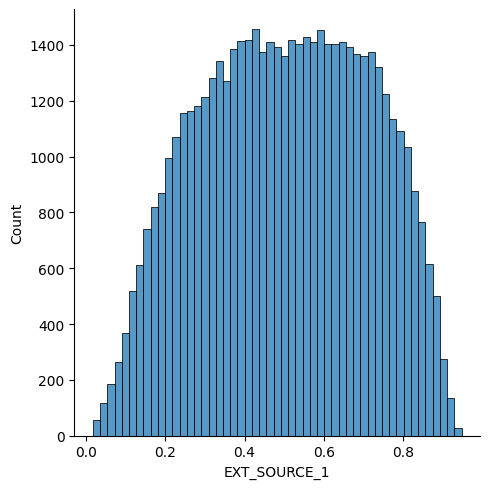

In [ ]:
# The distribution of EXT_SOURCE_1
sns.displot(data=train, x="EXT_SOURCE_1")
plt.show()

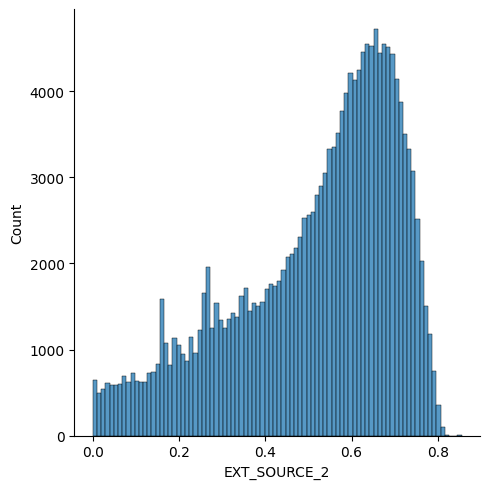

In [ ]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_2")
plt.show()

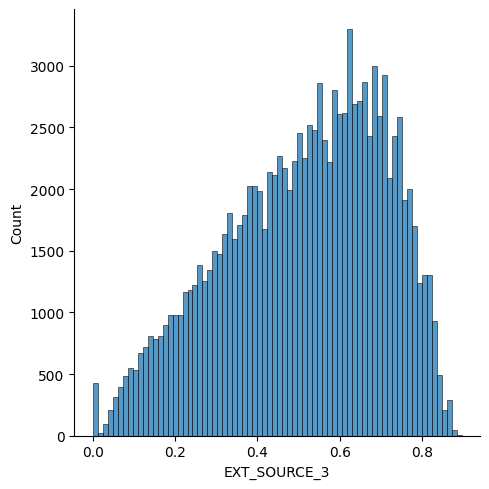

In [ ]:
# The distribution of EXT_SOURCE_3
sns.displot(data=train, x="EXT_SOURCE_3")
plt.show()

We can see that `EXT_SOURCE_*` is normalized between 0 and 1 (scores from outside credit agencies). It seems we can handle these features as they are. Let's check whether they really separate customers who default from those who do not. The cell below shows the default rate for ten groups of customers, from the lowest to the highest average external score.

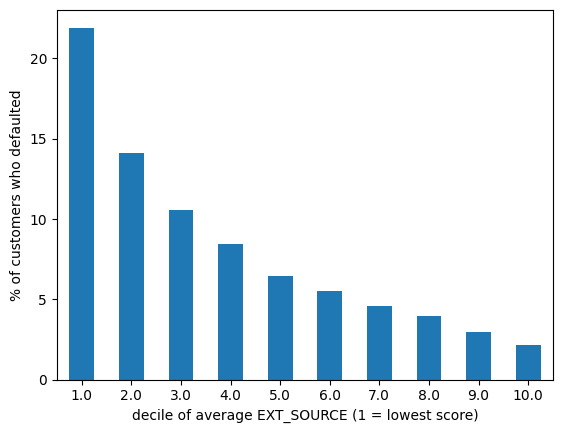

In [ ]:
# Default rate by decile of the average external score
ext_mean = train[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1)
decile = pd.qcut(ext_mean, 10, labels=False, duplicates="drop") + 1
rate = train.groupby(decile)["TARGET"].mean() * 100
rate.plot.bar(rot=0)
plt.xlabel("decile of average EXT_SOURCE (1 = lowest score)")
plt.ylabel("% of customers who defaulted")
plt.show()

The lowest-scoring group defaults about 22% of the time and the highest-scoring group only about 2%, roughly **10 times** less. A single feature already separates risky from safe customers, so these are the most important features in this data.

**Findings**:<br>
* No additional preprocessing is needed for the values themselves
* The three scores can be combined (average, min, max) into new features
* Many values are missing (70% / 0.2% / 32%): we need to decide what to do about that

#### AMT_INCOME_TOTAL column

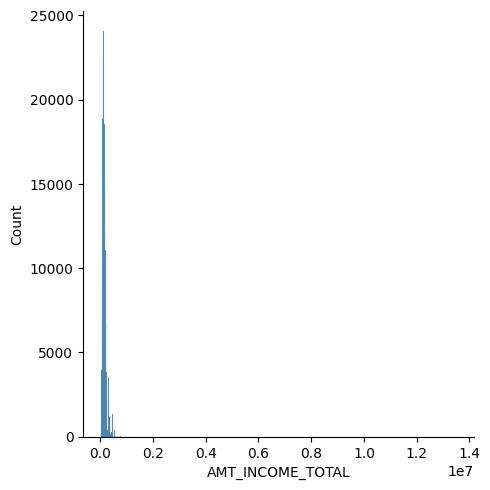

In [ ]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="AMT_INCOME_TOTAL")
plt.show()

The visualization of `AMT_INCOME_TOTAL` is hard to interpret. This may be caused by the presence of a small number of outliers that take large values. To visualize data like this, a logarithmic transformation can be effective.

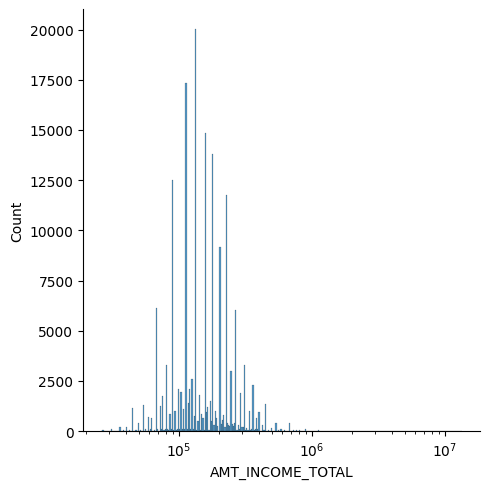

In [ ]:
# The distribution of AMT_INCOME_TOTAL（Logarithmic transformation）
sns.displot(data=train, x="AMT_INCOME_TOTAL", log_scale=10)
plt.show()

We displayed the graph successfully by using logarithmic transformation. The income is supposed to be a continuous value, but it looks like a discrete value. Let's have a look at the type of `AMT_INCOME_TOTAL` values.

In [ ]:
# Check the type of AMT_INCOME_TOTAL values
len(train["AMT_INCOME_TOTAL"].unique())

1641

In [ ]:
# Top 10 values of AMT_INCOME_TOTAL
train["AMT_INCOME_TOTAL"].value_counts().head(10)

,count
AMT_INCOME_TOTAL,
135000.0,19969
112500.0,17320
157500.0,14772
180000.0,13791
90000.0,12481
225000.0,11573
202500.0,9128
67500.0,6130
270000.0,6006


There are 171202 data in train, but `AMT_INCOME_TOTAL` consists of only 1641 different values. It appears that `AMT_INCOME_TOTAL` is not an exact annual income, but rather data compiled from a rounded number.

Tree-based models (LightGBM, CatBoost) only look at the *order* of the values when they split, so very large outliers do not disturb them the way they would disturb a linear model. That is why we do not need to remove outliers or apply a log transformation for the models.

**Findings**:<br>
* The outliers do not need to be removed for tree-based models
* Income is more useful *relative to* the loan size (ratios), which we will create in Section 4

#### OWN_CAR_AGE column

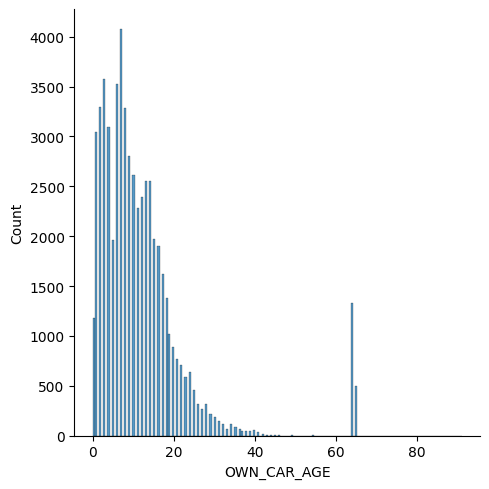

In [ ]:
# The distribution of OWN_CAR_AGE
sns.displot(data=train, x="OWN_CAR_AGE")
plt.show()

`OWN_CAR_AGE` can be inferred to be in years from the scale of values. In addition, the distribution is natural from 0 to 40, but there is an unnatural distribution around 60 to 70. It is hard to imagine that the number of years a car has been purchased increases suddenly like this, so they are considered to be outliers. About 1,800 customers have such values.

**Findings**:<br>
* Treat numbers above 60 as outliers

#### DAYS_EMPLOYED column

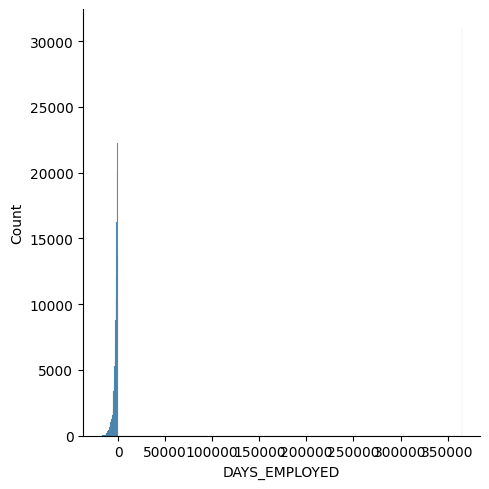

rows with DAYS_EMPLOYED == 365243: 30898


In [ ]:
# The distribution of DAYS_EMPLOYED
sns.displot(data=train, x="DAYS_EMPLOYED")
plt.show()
print("rows with DAYS_EMPLOYED == 365243:", (train["DAYS_EMPLOYED"] == 365243).sum())

This column counts the days since the customer started the current job, as a *negative* number (days before the application). There is a huge spike at **365243**, which is about **1000 years**. That is impossible, so it must be a code for "not employed" (for example pensioners). About 30,000 customers have it, which is the same number as the "XNA" in `ORGANIZATION_TYPE`. Let's check whether these customers behave differently.

In [ ]:
# Default rate with the placeholder vs with a real value
flag = train["DAYS_EMPLOYED"] == 365243
print(f"default rate with 365243 : {train.loc[flag, 'TARGET'].mean():.2%}")
print(f"default rate otherwise   : {train.loc[~flag, 'TARGET'].mean():.2%}")

default rate with 365243 : 5.42%
default rate otherwise   : 8.66%


The two groups behave differently (about 5.4% vs 8.7%), so the placeholder carries information. But if we leave it as a number, any calculation with it (such as "days employed divided by age") becomes nonsense. The solution is to turn it into a *missing value*: the model can still learn "employment unknown" as its own group.

**Findings**:<br>
* Treat 365243 in `DAYS_EMPLOYED` as a missing value

#### DAYS_BIRTH column

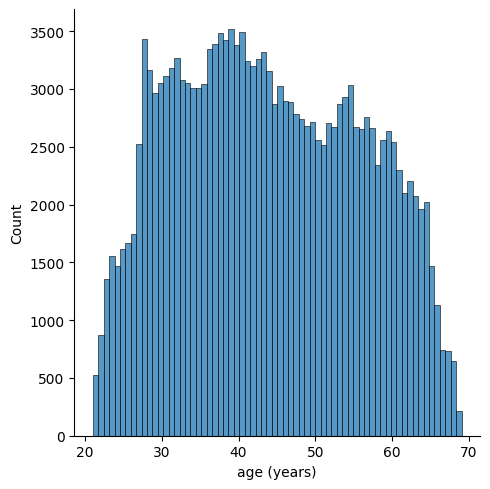

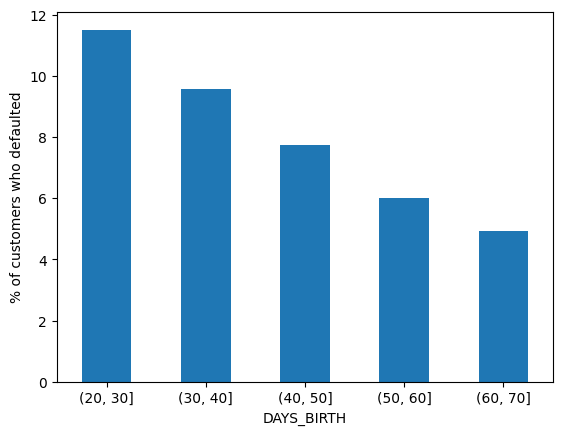

In [ ]:
# Age in years (DAYS_BIRTH is the negative number of days before the application)
age_years = -train["DAYS_BIRTH"] / 365.25
sns.displot(x=age_years)
plt.xlabel("age (years)")
plt.show()

# Default rate by age group
age_group = pd.cut(age_years, [20, 30, 40, 50, 60, 70])
(train.groupby(age_group)["TARGET"].mean() * 100).plot.bar(rot=0)
plt.ylabel("% of customers who defaulted")
plt.show()

`DAYS_BIRTH` is the age expressed in negative days. Converting it to years gives customers from 21 to 69 years old. **Younger customers default more often** (about 11.5% for 20 to 30 years vs about 5% above 60), so this is a useful feature as it is.

**Findings**:<br>
* No preprocessing is needed. Age can also be used to build ratios (for example how large a share of life was spent in the current job)

#### Loan amount, repayment and income

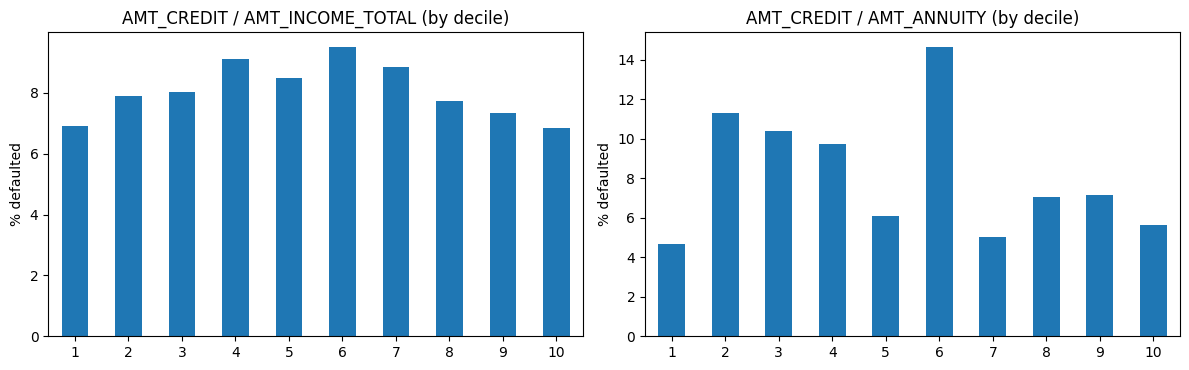

In [ ]:
# Default rate by decile of two ratios: loan size relative to income, and loan "term" (credit / annuity)
credit_income = train["AMT_CREDIT"] / train["AMT_INCOME_TOTAL"]
credit_term = train["AMT_CREDIT"] / train["AMT_ANNUITY"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, values) in zip(axes, [("AMT_CREDIT / AMT_INCOME_TOTAL", credit_income), ("AMT_CREDIT / AMT_ANNUITY", credit_term)]):
    groups = pd.qcut(values, 10, labels=False, duplicates="drop") + 1
    (train.groupby(groups)["TARGET"].mean() * 100).plot.bar(ax=ax, rot=0)
    ax.set_title(name + " (by decile)")
    ax.set_ylabel("% defaulted")
plt.tight_layout()
plt.show()

A single column such as `AMT_CREDIT` says little by itself: a 500,000 loan is small for a rich customer and heavy for a poor one. The **ratios** reveal patterns that the raw columns hide, but note that the patterns are **not straight lines**:

* For `AMT_CREDIT / AMT_INCOME_TOTAL`, the default rate rises from about 7% to about 9.5% and then falls back to about 7% for the largest ratios.
* For `AMT_CREDIT / AMT_ANNUITY` (a proxy for the loan term) it is very jagged, from about 5% to almost 15%, because loans come with standard terms and some terms are much riskier than others.

Models that split on one column at a time have difficulty discovering such ratios by themselves, so **we will create them as new features**. And because the patterns are irregular, a model that can learn non-linear effects (like a tree model) is needed to use them.

**Findings**:<br>
* Create ratio features from the loan amount, repayment, income, family size and age

### 3.3 Which features are related to the target?
Finally, let's look at the linear correlation between each numeric feature and `TARGET`.

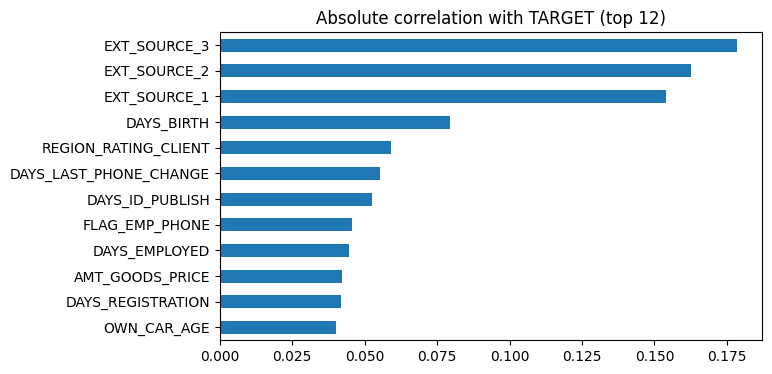

In [ ]:
# Absolute correlation with TARGET for the numeric features
num_features = train.drop(columns="TARGET").select_dtypes(include="number")
corr = num_features.corrwith(train["TARGET"]).abs().sort_values(ascending=False)
corr.head(12)[::-1].plot.barh(figsize=(7, 4), title="Absolute correlation with TARGET (top 12)")
plt.show()

The `EXT_SOURCE_*` features are the strongest, as expected. But note that **even the strongest correlation is below 0.2**: no single feature explains default, and relationships are often non-linear. This is a good situation for tree-based models, which combine many weak signals and capture non-linear effects automatically.

Up to this point, we have visualized and analyzed the main features. Visualization requires some ingenuity, and it can deepen your understanding of data.

**Findings**:<br>
* Combine many weak signals: tree-based boosting models are a good fit

### **[Next Steps]**
> + Visualize the features that are not covered here (for example `NAME_EDUCATION_TYPE`, `OCCUPATION_TYPE`, `REGION_RATING_CLIENT`). Is the feature categorical or continuous? What type of graph is most effective to understand it?
> + What do you notice about the features? What kind of preprocessing is needed?

## 4.Preprocessing and Feature Creation

Here, we will conduct the preprocessing and create new features based on what we have learned in the preceding visualization and analysis.

### 4.1 Combine train and test
In `tutorial.ipynb` the same preprocessing was written twice, once for `train` and once for `test`, and statistics such as the mean were taken from the train data only. Here, every step we apply uses **no target information** (we only replace placeholder codes and compute ratios between columns of the same customer), so there is no risk of leaking the answer. That allows us to **stack train and test into one table, process it once, and split it back at the end**. It guarantees that train and test are treated in exactly the same way.

**IMPORTANT**: the target is set aside first, and never goes into the combined table.

In [ ]:
n_train = len(train)                     # remember where train ends and test begins
y = train["TARGET"].values

df = pd.concat([train.drop(columns="TARGET"), test], axis=0, ignore_index=True)
print("combined table:", df.shape)       # train rows + test rows, 32 features

combined table: (232702, 32)


### ORGANIZATION_TYPE and CODE_GENDER columns
As found in Section 3, "XNA" means "unknown". We replace it with a missing value (`NaN`).

In [ ]:
# Treat "XNA" as missing values
df["ORGANIZATION_TYPE"] = df["ORGANIZATION_TYPE"].replace("XNA", np.nan)
df["CODE_GENDER"] = df["CODE_GENDER"].replace("XNA", np.nan)

### DAYS_EMPLOYED column
The impossible value 365243 (about 1000 years) is replaced with a missing value.

In [ ]:
# Treat 365243 in DAYS_EMPLOYED as a missing value
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)

### OWN_CAR_AGE column
First, we will replace the unnatural outliers that are over 60 as `np.nan` (missing values).

In [ ]:
# Treat values above 60 (outliers) in OWN_CAR_AGE as missing values
df.loc[df["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan

### 4.2 Missing values: we leave them as they are
In `tutorial.ipynb`, missing values were filled with the mean, and `OWN_CAR_AGE` was grouped by decade and one-hot encoded (because the models used there cannot read missing values). We do something different on purpose, for three reasons:

1. **LightGBM and CatBoost handle missing values natively.** At every split they learn which side the missing values should go to.
2. **"Missing" can be information.** Filling with the mean would erase it. Let's check this with the data.
3. A mean fill **invents data** that does not exist: for `OWN_CAR_AGE`, two thirds of the values would be fake.

In [ ]:
# Is "the value is missing" related to default?  (train rows only)
train_part = df.iloc[:n_train]
for col in ["EXT_SOURCE_1", "EXT_SOURCE_3", "OWN_CAR_AGE", "AMT_REQ_CREDIT_BUREAU_YEAR", "DAYS_EMPLOYED"]:
    is_missing = train_part[col].isna().values
    print(f"{col:28s} default rate if missing: {y[is_missing].mean():6.2%}   if present: {y[~is_missing].mean():6.2%}")

EXT_SOURCE_1                 default rate if missing:  8.33%   if present:  7.49%
EXT_SOURCE_3                 default rate if missing:  8.86%   if present:  7.71%
OWN_CAR_AGE                  default rate if missing:  8.50%   if present:  7.20%
AMT_REQ_CREDIT_BUREAU_YEAR   default rate if missing: 10.38%   if present:  7.71%
DAYS_EMPLOYED                default rate if missing:  5.42%   if present:  8.66%


The default rate differs between "missing" and "present" for several columns (for example `AMT_REQ_CREDIT_BUREAU_YEAR` about 10.4% vs 7.7%, `EXT_SOURCE_3` about 8.9% vs 7.7%, and `DAYS_EMPLOYED` about 5.4% vs 8.7%), so the *fact* of being missing carries signal. By leaving `NaN` as it is, the models can use it.

**Findings**:<br>
* Do not fill missing values for the tree-based models

### 4.3 Text columns
`tutorial.ipynb` converted text columns with Label Encoding, Count Encoding and One Hot Encoding. We have 8 text columns: `NAME_CONTRACT_TYPE`, `CODE_GENDER`, `NAME_INCOME_TYPE`, `NAME_EDUCATION_TYPE`, `NAME_FAMILY_STATUS`, `NAME_HOUSING_TYPE`, `OCCUPATION_TYPE` and `ORGANIZATION_TYPE`. Instead of encoding them by hand, we will give them to the models as they are:

- **LightGBM** accepts columns of pandas type `category`. It finds the best way to *group* the categories at each split.
- **CatBoost** replaces each category by the average default rate of that category, computed in a special "ordered" way so that a customer's own answer is never used to describe themselves (that would be cheating).

We will convert the columns to the `category` type after we create the new features (Section 4.7).

### 4.4 Feature creation: ratios
Trees ask questions about **one column at a time** ("is `AMT_INCOME_TOTAL` below 100,000?"). A fact such as "the loan is 8 times the yearly income" involves *two* columns, and a tree would need many splits to approximate it. So we compute the ratio ourselves and hand it over as a new column. First, a helper function. A zero in the denominator becomes `NaN` instead of infinity.

In [ ]:
def ratio(frame, a, b, name):
    # frame[a] / frame[b]; a zero in the denominator becomes NaN instead of infinity
    frame[name] = frame[a] / frame[b].replace(0, np.nan)

#### CREDIT_INCOME: how large is the loan compared with the income?

In [ ]:
ratio(df, "AMT_CREDIT", "AMT_INCOME_TOTAL", "CREDIT_INCOME")

#### ANNUITY_INCOME: which share of the income goes to the repayments?

In [ ]:
ratio(df, "AMT_ANNUITY", "AMT_INCOME_TOTAL", "ANNUITY_INCOME")

#### CREDIT_TERM: roughly how many payments? (loan size divided by one repayment)

In [ ]:
ratio(df, "AMT_CREDIT", "AMT_ANNUITY", "CREDIT_TERM")

#### GOODS_CREDIT: which share of the loan buys the goods?

In [ ]:
ratio(df, "AMT_GOODS_PRICE", "AMT_CREDIT", "GOODS_CREDIT")

#### EMPLOYED_BIRTH: which share of life was spent in the current job? (job stability)

In [ ]:
ratio(df, "DAYS_EMPLOYED", "DAYS_BIRTH", "EMPLOYED_BIRTH")

#### INCOME_PER_PERSON: income shared by the family members

In [ ]:
ratio(df, "AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS", "INCOME_PER_PERSON")

### 4.5 Feature creation: summaries of the external scores
The three external scores are the strongest features. We combine them into four new features: the average, the lowest, the highest and the product. For example, "the most pessimistic agency" (`EXT_MIN`) can matter more than the average.

`mean`, `min` and `max` ignore missing values, so a customer with only one score still gets a value. The product is `NaN` if any score is missing.

In [ ]:
ext = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
df["EXT_MEAN"] = df[ext].mean(axis=1)                      # average of the available scores
df["EXT_MIN"] = df[ext].min(axis=1)                        # most pessimistic score
df["EXT_MAX"] = df[ext].max(axis=1)                        # most optimistic score
df["EXT_PROD"] = df[ext].prod(axis=1, skipna=False)        # product (NaN if one score is missing)

Do the new features carry signal? Let's compare them with the original features, using the absolute correlation with `TARGET` (train rows only).

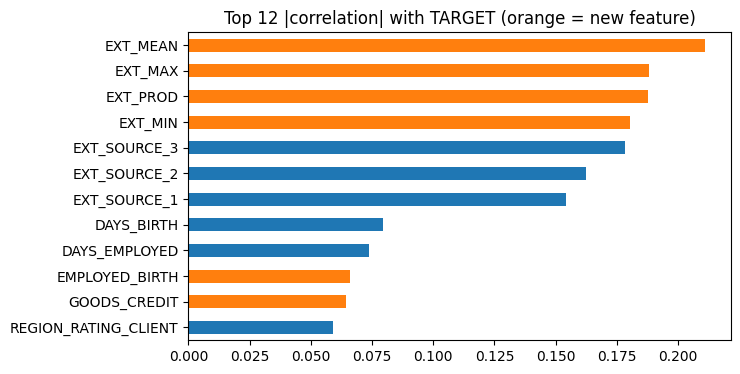

In [ ]:
new_features = ["CREDIT_INCOME", "ANNUITY_INCOME", "CREDIT_TERM", "GOODS_CREDIT", "EMPLOYED_BIRTH", "INCOME_PER_PERSON",
                "EXT_MEAN", "EXT_MIN", "EXT_MAX", "EXT_PROD"]
check = df.iloc[:n_train].select_dtypes(include="number")
corr_all = check.corrwith(pd.Series(y)).abs().sort_values(ascending=False)
colors = ["tab:orange" if c in new_features else "tab:blue" for c in corr_all.head(12).index]
corr_all.head(12)[::-1].plot.barh(figsize=(7, 4), color=colors[::-1], title="Top 12 |correlation| with TARGET (orange = new feature)")
plt.show()

Four of the new features (`EXT_MEAN`, `EXT_MAX`, `EXT_PROD` and `EXT_MIN`) are more strongly related to the target than any of the three original scores, and `EXT_MEAN` is the strongest of all (about 0.21). The other new features, such as `CREDIT_TERM`, do not show up here because their relation to the target is not a straight line (see Section 3.2): a correlation cannot see it, but the models can. We now have **42 features** (32 original + 10 new). We keep a copy of this table, because two of our three models use it.

In [ ]:
df_42 = df.copy()
print("number of features:", df_42.shape[1])

number of features: 42


### 4.6 A bigger feature set (112 features) for the third model
Would **even more** features be better? We tested it: with the same model, 42 features gave an out-of-fold AUC of 0.7587, 60 features 0.7586, and 112 features 0.7582. So more features alone did **not** help, they only added noise.

But a model trained on *different inputs* makes *different mistakes*, and that is exactly what an ensemble needs. So the third model of our blend uses a bigger feature set. It is built in two steps.

**Step 1: 18 extra features** (more ratios, interactions between the external scores and age or job length, the number of blank fields per customer, and the total number of bureau enquiries).

In [ ]:
df_big = df_42.copy()

df_big["AGE_YEARS"] = -df_big["DAYS_BIRTH"] / 365.25                 # age in years
df_big["EMPLOYED_YEARS"] = -df_big["DAYS_EMPLOYED"] / 365.25         # years in the current job
ratio(df_big, "AMT_ANNUITY", "AMT_CREDIT", "ANNUITY_CREDIT")         # repayment relative to the loan
df_big["CREDIT_GOODS_DIFF"] = df_big["AMT_CREDIT"] - df_big["AMT_GOODS_PRICE"]   # loan beyond the goods price
ratio(df_big, "OWN_CAR_AGE", "DAYS_BIRTH", "CAR_AGE_BIRTH")
ratio(df_big, "DAYS_REGISTRATION", "DAYS_BIRTH", "REGISTRATION_BIRTH")
ratio(df_big, "DAYS_ID_PUBLISH", "DAYS_BIRTH", "ID_PUBLISH_BIRTH")
ratio(df_big, "DAYS_LAST_PHONE_CHANGE", "DAYS_BIRTH", "PHONE_CHANGE_BIRTH")
ratio(df_big, "AMT_CREDIT", "CNT_FAM_MEMBERS", "CREDIT_PER_PERSON")
ratio(df_big, "CNT_CHILDREN", "CNT_FAM_MEMBERS", "CHILDREN_RATIO")

In [ ]:
# More summaries of the external scores, and interactions with age, job length and loan term
df_big["EXT_STD"] = df_big[ext].std(axis=1)                          # how much the agencies disagree
df_big["EXT_WEIGHTED"] = (df_big["EXT_SOURCE_1"] * 2 + df_big["EXT_SOURCE_2"] * 3 + df_big["EXT_SOURCE_3"] * 4) / 9
df_big["EXT_MEAN_X_CREDIT_TERM"] = df_big["EXT_MEAN"] * df_big["CREDIT_TERM"]
df_big["EXT_MEAN_X_AGE"] = df_big["EXT_MEAN"] * df_big["AGE_YEARS"]
df_big["EXT_MEAN_X_EMPLOYED"] = df_big["EXT_MEAN"] * df_big["EMPLOYED_YEARS"]
df_big["EXT2_X_EXT3"] = df_big["EXT_SOURCE_2"] * df_big["EXT_SOURCE_3"]

In [ ]:
# How many fields did the customer leave blank?  And the total number of credit-bureau enquiries
df_big["N_MISSING"] = df_big.isna().sum(axis=1)
bureau = ["AMT_REQ_CREDIT_BUREAU_HOUR", "AMT_REQ_CREDIT_BUREAU_MON", "AMT_REQ_CREDIT_BUREAU_QRT", "AMT_REQ_CREDIT_BUREAU_YEAR"]
df_big["BUREAU_TOTAL"] = df_big[bureau].sum(axis=1, skipna=False)
print("number of features:", df_big.shape[1])

number of features: 60


**Step 2: "compared with similar customers" features (group statistics).** For each of four text columns (organization, occupation, income type, education) we compute the *average* income, credit, annuity, external score, age and job length of the group, and the customer's *difference* from that average. In words: "is this customer richer or poorer than other people in the same job?" We also add how common each category is (a "frequency encoding").

These features use only the feature columns, never the target, so there is no leakage.

In [ ]:
groups = ["ORGANIZATION_TYPE", "OCCUPATION_TYPE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE"]
targets = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "EXT_MEAN", "AGE_YEARS", "EMPLOYED_YEARS"]
for g in groups:
    for t in targets:
        group_mean = df_big.groupby(g, observed=True)[t].transform("mean")   # average of the customer's group
        df_big[f"{t}_MEAN_BY_{g}"] = group_mean
        df_big[f"{t}_DIFF_{g}"] = df_big[t] - group_mean                     # customer minus group average

# frequency encoding: how common is each category? (share of customers)
for g in groups:
    df_big[f"{g}_FREQ"] = df_big[g].map(df_big[g].value_counts(normalize=True))

print("number of features:", df_big.shape[1])

number of features: 112


### 4.7 Convert text columns to the `category` type
This is the step announced in Section 4.3. We do it for both tables. For CatBoost we will prepare plain text columns later (Section 5.2).

In [ ]:
# The text columns (everything that is not numeric)
cat_cols = [c for c in df_42.columns if not pd.api.types.is_numeric_dtype(df_42[c])]
print("text columns:", cat_cols)

# CatBoost needs plain text (no NaN): keep a copy before the conversion
df_cat = df_42.copy()
for c in cat_cols:
    df_cat[c] = df_cat[c].astype(object).fillna("NA").astype(str)

# LightGBM: convert to the category type
for c in cat_cols:
    df_42[c] = df_42[c].astype("category")
    df_big[c] = df_big[c].astype("category")

text columns: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']


### 4.8 Split back into train and test

In [ ]:
X_42, X_42_test = df_42.iloc[:n_train], df_42.iloc[n_train:]        # 42 features
X_big, X_big_test = df_big.iloc[:n_train], df_big.iloc[n_train:]    # 112 features
X_cat, X_cat_test = df_cat.iloc[:n_train], df_cat.iloc[n_train:]    # 42 features, text version for CatBoost

print("42 features :", X_42.shape, X_42_test.shape)
print("112 features:", X_big.shape, X_big_test.shape)

42 features : (171202, 42) (61500, 42)
112 features: (171202, 112) (61500, 112)


### **[Next Steps]**
> + Apply preprocessing to the features you did not visualize. Is it correctly preprocessed?
> + Create new features of your own from the column descriptions (ratios and differences between related columns are a good start), then check with cross-validation (Section 5.3) whether they improve the score. Remember that **more features did not help here**: keep only what raises the score.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#).

## 5.Building the Machine Learning Model

Now, we are ready to start building the machine learning model.

### 5.1 Import Additional Libraries
First, we import the necessary libraries for training and evaluation.

- `StratifiedKFold`: Split the data into several folds, keeping the share of defaults equal in every fold.
- `train_test_split`: Split data into training and evaluation data (used for the holdout example).
- `roc_auc_score`, `roc_curve`: Calculate ROC-AUC, the evaluation metric for this competition, and draw the curve.
- `lightgbm`: A fast gradient-boosting library.
- `catboost`: Another gradient-boosting library, good with text (categorical) columns.

We also collect all the settings in one place. Random **seeds** make the results reproducible: running the notebook again gives the same numbers.

In [ ]:
%pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 45.7 MB/s  0:00:02


In [ ]:
# Importing libraries
import time
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

In [ ]:
# Settings
N_FOLDS = 5                  # number of folds for cross-validation
SEEDS_LGBM = [0, 1, 2]       # seeds for the LightGBM model on 42 features
SEEDS_CAT = [0]              # seeds for the CatBoost model
SEEDS_LGBM_BIG = [10, 11]    # seeds for the LightGBM model on 112 features
LGBM_TREES = 8000            # maximum number of trees (early stopping chooses the real number)
CAT_TREES = 4000             # maximum number of trees for CatBoost

### 5.2 Preparing the Data
We already split the data into explanatory variables (`X_*`) and the target (`y`) in Section 4. Here we only check the shapes.

**Note: no standardization this time.** `tutorial.ipynb` standardized the data (mean 0, variance 1) because logistic regression needs it. Tree-based models split on thresholds ("is the value above 0.4?"), so the scale of a column makes no difference to them, and we skip this step.

In [ ]:
print("X_42  :", X_42.shape, "| X_big:", X_big.shape, "| X_cat:", X_cat.shape)
print("y     :", y.shape, f"| default rate {y.mean():.2%}")

X_42  : (171202, 42) | X_big: (171202, 112) | X_cat: (171202, 42)
y     : (171202,) | default rate 8.07%


### 5.3 How should we evaluate the model?
**ROC-AUC in one sentence.** Pick one customer who defaulted and one who did not. AUC is the probability that the model gives the defaulter the **higher** risk score:

$$\text{AUC}=P\big(\hat p_{\text{defaulter}}>\hat p_{\text{non-defaulter}}\big)$$

AUC = 0.5 is a coin flip and 1.0 is a perfect ranking. Only the *order* of the scores matters, not their exact values.

**Holdout method (as in `tutorial.ipynb`).** We keep 30% of the training data aside and judge the model on it. Let's try it with a first LightGBM model.

In [ ]:
# A quick first model: LightGBM with simple settings
quick_params = dict(objective="binary", learning_rate=0.1, n_estimators=500, num_leaves=31,
                    verbose=-1, n_jobs=-1, random_state=0)

# Split the original data into the training data and the validation data (70% / 30%)
X_train, X_valid, y_train, y_valid = train_test_split(X_42, y, test_size=0.3, stratify=y, random_state=0)

model = lgb.LGBMClassifier(**quick_params)
model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], eval_metric="auc",
          callbacks=[lgb.early_stopping(50, verbose=False)])
valid_pred = model.predict_proba(X_valid)[:, 1]
print(f"Holdout valid score: {roc_auc_score(y_valid, valid_pred):.4f}   (trees used: {model.best_iteration_})")

Holdout valid score: 0.7501   (trees used: 49)


This gives **one number**. But is it reliable? If we split the data differently we would get a different number. Let's repeat the experiment with 5 different splits. This is called **cross-validation**:

1. Split the training data into 5 equal parts (**folds**), keeping the same share of defaults in each part (**stratified**).
2. Train on 4 parts and predict the 5th. Repeat 5 times so that every part is predicted once.
3. Stitch the 5 sets of predictions together. These are the **out-of-fold (OOF) predictions**: every customer is predicted by a model that has *never seen that customer*.
4. Compute the AUC on all the OOF predictions. It is our best estimate of the score on new data.

In [ ]:
# 5-fold cross-validation with the same quick model
oof = np.zeros(len(X_42))
fold_scores = []
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=0)
for fold, (tr_idx, va_idx) in enumerate(skf.split(X_42, y)):
    m = lgb.LGBMClassifier(**quick_params)
    m.fit(X_42.iloc[tr_idx], y[tr_idx], eval_set=[(X_42.iloc[va_idx], y[va_idx])], eval_metric="auc",
          callbacks=[lgb.early_stopping(50, verbose=False)])
    oof[va_idx] = m.predict_proba(X_42.iloc[va_idx])[:, 1]
    fold_scores.append(roc_auc_score(y[va_idx], oof[va_idx]))
    print(f"fold {fold}: AUC = {fold_scores[-1]:.4f}")

print(f"\nspread between folds: {min(fold_scores):.4f} to {max(fold_scores):.4f}")
print(f"OOF AUC over all training customers: {roc_auc_score(y, oof):.4f}")

fold 0: AUC = 0.7572
fold 1: AUC = 0.7532
fold 2: AUC = 0.7499
fold 3: AUC = 0.7508
fold 4: AUC = 0.7534

spread between folds: 0.7499 to 0.7572
OOF AUC over all training customers: 0.7529


The five folds give different scores (a spread of several thousandths of AUC). A single holdout number can therefore be a bit lucky or unlucky, while the OOF AUC uses **all 171,202 customers** and is much steadier. From now on, we judge every model by its **OOF AUC**.

**Why not trust the public leaderboard instead?** It only scores a *subset* of the test rows, so it is noisy. Differences smaller than about 0.002 there are mostly noise.

**Findings**:<br>
* Use stratified 5-fold cross-validation and the OOF AUC to compare models
* Repeat with several seeds and average, to reduce the influence of one particular split

### 5.4 Gradient boosting and its hyperparameters
`tutorial.ipynb` used logistic regression and random forest. We use **gradient boosting**, which builds many small decision trees, one after another, where **each new tree corrects the mistakes of the trees before it**:

$$F_m(x)=F_{m-1}(x)+\eta\cdot T_m(x)$$

- $F_m$ is the model after $m$ trees and $T_m$ is the new small tree.
- The model's raw output $F$ is turned into a probability with the sigmoid, $\hat p=\frac{1}{1+e^{-F}}$.
- Each tree is trained on the **errors** of the current model. For the log-loss used here, the error of a customer is simply $y-\hat p$ ("what happened" minus "what we predicted").
- $\eta$ is the **learning rate**: a small value (such as 0.02) means that every tree only nudges the prediction, which is slower but more accurate.
- **Early stopping**: we stop adding trees when the score on the validation fold has not improved for 200 rounds. This protects against **overfitting** (memorizing noise).

The settings of the model are called **hyperparameters**. The most important ones:

| Hyperparameter | Meaning | Larger value means |
|---|---|---|
| `learning_rate` | size of each correction | faster but coarser learning |
| `num_leaves` | leaves per tree (complexity) | more complex trees, more risk of overfitting |
| `min_child_samples` | minimum customers in a leaf | smoother, safer leaves |
| `colsample_bytree` | share of columns each tree may use | (smaller = more randomness, less overfitting) |
| `subsample` | share of rows each tree sees | (smaller = more randomness) |
| `reg_lambda`, `reg_alpha` | penalties on the size of the leaf values | stronger shrinkage |
| `min_split_gain` | minimum improvement needed to split | fewer useless splits |
| `max_bin` | number of bins per numeric column | finer thresholds, slower |

### 5.5 Hyperparameter tuning with Optuna
There is no formula for the best hyperparameters, so we **search**. **Optuna** keeps a record of which settings scored well and proposes new settings in the promising region (smarter than trying at random). Every candidate is scored with 5-fold cross-validation.

We ran 22 trials. The first trial used the settings we had before tuning, as a reference:

| | `num_leaves` | `min_child_samples` | `colsample_bytree` | OOF AUC |
|---|---|---|---|---|
| before tuning | 31 | 100 | 0.60 | 0.7589 |
| **best found** | **17** | **31** | **0.32** | **0.7611** |

The best settings use **smaller trees that each see only about a third of the columns**. With weak and noisy signals, less complex and more random models generalize better.

The search takes about 20 minutes, so it is switched off by default (`RUN_TUNING = False`) and the best settings are written in `BEST_LGBM`. Set `RUN_TUNING = True` to run the search yourself.

In [ ]:
# The best hyperparameters found by the Optuna search
BEST_LGBM = dict(num_leaves=17, min_child_samples=31, colsample_bytree=0.3162830910532151,
                 subsample=0.9676518602101859, reg_alpha=0.5426546814932669, reg_lambda=9.567046336564795,
                 min_split_gain=0.19086136725626857, max_bin=255)

RUN_TUNING = False    # set to True to run the search again (about 20 minutes)

In [ ]:
if RUN_TUNING:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    tune_folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(X_42, y))

    def objective(trial):
        params = dict(objective="binary", metric="auc", learning_rate=0.05, n_estimators=3000, verbose=-1, n_jobs=-1,
                      num_leaves=trial.suggest_int("num_leaves", 6, 64),
                      min_child_samples=trial.suggest_int("min_child_samples", 20, 500),
                      colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 0.9),
                      subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
                      reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
                      reg_lambda=trial.suggest_float("reg_lambda", 1e-2, 50, log=True),
                      min_split_gain=trial.suggest_float("min_split_gain", 0.0, 0.5),
                      max_bin=trial.suggest_categorical("max_bin", [63, 127, 255]))
        oof_t = np.zeros(len(X_42))
        for tr_idx, va_idx in tune_folds:
            m = lgb.LGBMClassifier(random_state=0, **params)
            m.fit(X_42.iloc[tr_idx], y[tr_idx], eval_set=[(X_42.iloc[va_idx], y[va_idx])],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
            oof_t[va_idx] = m.predict_proba(X_42.iloc[va_idx])[:, 1]
        return roc_auc_score(y, oof_t)

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
    study.optimize(objective, n_trials=22)
    print("best OOF AUC:", study.best_value)
    BEST_LGBM = study.best_params
    print(BEST_LGBM)

### 5.6 Model 1: LightGBM on the 42 features
**LightGBM** grows its trees *leaf-wise* (it always splits the leaf that improves the model the most) and uses histograms of the column values, which makes it very fast. It handles missing values and `category` columns natively.

We write one training function and use it twice (for model 1 and model 3). For every seed, it runs the 5-fold cross-validation. Each of the models also predicts the **test** data, and all those test predictions are averaged.

In [ ]:
def train_lightgbm(X, y, X_test, params, seeds):
    # Cross-validated LightGBM. Returns OOF predictions, averaged test predictions, fold scores and feature importance.
    oof = np.zeros(len(X))
    test_pred = np.zeros(len(X_test))
    fold_scores = []
    importance = np.zeros(X.shape[1])
    for seed in seeds:
        skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
        for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
            model = lgb.LGBMClassifier(random_state=seed, **params)
            model.fit(X.iloc[tr_idx], y[tr_idx],
                      eval_set=[(X.iloc[va_idx], y[va_idx])],
                      callbacks=[lgb.early_stopping(200, verbose=False)])
            # every customer is predicted once per seed, then averaged over the seeds
            oof[va_idx] += model.predict_proba(X.iloc[va_idx])[:, 1] / len(seeds)
            # every model also predicts the test data; average over all models
            test_pred += model.predict_proba(X_test)[:, 1] / (N_FOLDS * len(seeds))
            importance += model.booster_.feature_importance("gain")
            fold_scores.append(model.best_score_["valid_0"]["auc"])
            print(f"seed {seed} fold {fold}: AUC = {fold_scores[-1]:.4f}  (trees used: {model.best_iteration_})")
    return oof, test_pred, fold_scores, importance

In [ ]:
# Parameters of model 1: tuned hyperparameters + a small learning rate
lgbm_params = dict(objective="binary", metric="auc", learning_rate=0.02, n_estimators=LGBM_TREES,
                   subsample_freq=1, verbose=-1, n_jobs=-1, **BEST_LGBM)

start = time.time()
lgbm_oof, lgbm_test, lgbm_scores, lgbm_importance = train_lightgbm(X_42, y, X_42_test, lgbm_params, SEEDS_LGBM)
print(f"\ntraining time: {(time.time() - start) / 60:.1f} min")
print(f"LightGBM (42 features)  OOF AUC: {roc_auc_score(y, lgbm_oof):.4f}")

seed 0 fold 0: AUC = 0.7624  (trees used: 1301)
seed 0 fold 1: AUC = 0.7630  (trees used: 1783)
seed 0 fold 2: AUC = 0.7588  (trees used: 1709)
seed 0 fold 3: AUC = 0.7600  (trees used: 1688)
seed 0 fold 4: AUC = 0.7636  (trees used: 2026)
seed 1 fold 0: AUC = 0.7560  (trees used: 1296)
seed 1 fold 1: AUC = 0.7658  (trees used: 1718)
seed 1 fold 2: AUC = 0.7598  (trees used: 1551)
seed 1 fold 3: AUC = 0.7637  (trees used: 1947)
seed 1 fold 4: AUC = 0.7630  (trees used: 2283)
seed 2 fold 0: AUC = 0.7634  (trees used: 1382)
seed 2 fold 1: AUC = 0.7529  (trees used: 1424)
seed 2 fold 2: AUC = 0.7689  (trees used: 2310)
seed 2 fold 3: AUC = 0.7599  (trees used: 1004)
seed 2 fold 4: AUC = 0.7601  (trees used: 1335)

training time: 19.0 min
LightGBM (42 features)  OOF AUC: 0.7628


The OOF AUC of this single tuned model is about **0.763**. For comparison, the first LightGBM we made before tuning scored 0.761.

#### Which features did the model use most?
Tree models can tell us how much each feature contributed (the total improvement of the loss from all the splits that used the feature, called *gain*).

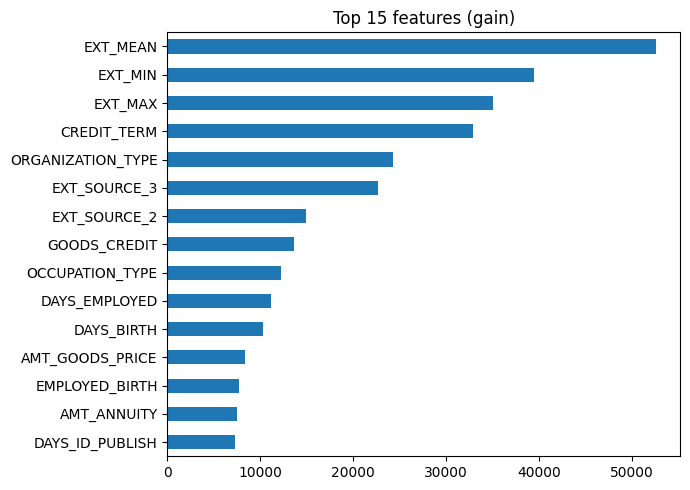

In [ ]:
# Feature importance (gain) averaged over all trained models
n_models = N_FOLDS * len(SEEDS_LGBM)
imp = pd.Series(lgbm_importance / n_models, index=X_42.columns).sort_values(ascending=False)
imp.head(15)[::-1].plot.barh(figsize=(7, 5), title="Top 15 features (gain)")
plt.tight_layout()
plt.show()

**The four most important features are all ones we created**: `EXT_MEAN`, `EXT_MIN`, `EXT_MAX` and `CREDIT_TERM`. The text column `ORGANIZATION_TYPE` comes next, then the original `EXT_SOURCE_3` and `EXT_SOURCE_2`, and another new feature, `GOODS_CREDIT`, is also in the top 10. This supports the ideas behind them. If a feature is always at the bottom, the model is telling you it does not help.

### 5.7 Model 2: CatBoost on the 42 features
Why a second model? **CatBoost** differs from LightGBM in ways that make its mistakes *different*:

- **Symmetric trees**: all the nodes at one depth ask the same question, so a tree of depth 6 is a table with 64 cells. This is a strong form of regularization.
- **Ordered target statistics** for text columns (see Section 4.3): each category is replaced by the average default rate of the customers that come *before* in a random order, so a customer's own label is never used to describe themselves.

CatBoost needs the text columns as plain text (`X_cat`), which we prepared in Section 4.7.

In [ ]:
def train_catboost(X, y, X_test, seeds):
    # Cross-validated CatBoost. Returns OOF predictions, averaged test predictions and fold scores.
    oof = np.zeros(len(X))
    test_pred = np.zeros(len(X_test))
    fold_scores = []
    for seed in seeds:
        skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
        for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y)):
            model = CatBoostClassifier(iterations=CAT_TREES, learning_rate=0.08, depth=6, l2_leaf_reg=6,
                                       eval_metric="AUC", random_seed=seed, verbose=0,
                                       od_type="Iter", od_wait=150, cat_features=cat_cols)
            model.fit(X.iloc[tr_idx], y[tr_idx], eval_set=(X.iloc[va_idx], y[va_idx]), use_best_model=True)
            oof[va_idx] += model.predict_proba(X.iloc[va_idx])[:, 1] / len(seeds)
            test_pred += model.predict_proba(X_test)[:, 1] / (N_FOLDS * len(seeds))
            fold_scores.append(model.get_best_score()["validation"]["AUC"])
            print(f"seed {seed} fold {fold}: AUC = {fold_scores[-1]:.4f}  (trees used: {model.get_best_iteration()})")
    return oof, test_pred, fold_scores

In [ ]:
start = time.time()
cat_oof, cat_test, cat_scores = train_catboost(X_cat, y, X_cat_test, SEEDS_CAT)
print(f"\ntraining time: {(time.time() - start) / 60:.1f} min")
print(f"CatBoost (42 features)  OOF AUC: {roc_auc_score(y, cat_oof):.4f}")

seed 0 fold 0: AUC = 0.7613  (trees used: 426)
seed 0 fold 1: AUC = 0.7603  (trees used: 864)
seed 0 fold 2: AUC = 0.7601  (trees used: 827)
seed 0 fold 3: AUC = 0.7594  (trees used: 676)
seed 0 fold 4: AUC = 0.7606  (trees used: 573)

training time: 27.7 min
CatBoost (42 features)  OOF AUC: 0.7603


### 5.8 Model 3: LightGBM on the 112 features
The same tuned LightGBM, trained on the bigger feature set from Section 4.6 (learning rate 0.03 and different seeds). Alone it is not better than model 1, but its mistakes are different, which helps the blend.

In [ ]:
lgbm_big_params = dict(lgbm_params, learning_rate=0.03)

start = time.time()
lgbm_big_oof, lgbm_big_test, lgbm_big_scores, _ = train_lightgbm(X_big, y, X_big_test, lgbm_big_params, SEEDS_LGBM_BIG)
print(f"\ntraining time: {(time.time() - start) / 60:.1f} min")
print(f"LightGBM (112 features) OOF AUC: {roc_auc_score(y, lgbm_big_oof):.4f}")

seed 10 fold 0: AUC = 0.7620  (trees used: 1195)
seed 10 fold 1: AUC = 0.7642  (trees used: 1060)
seed 10 fold 2: AUC = 0.7584  (trees used: 680)
seed 10 fold 3: AUC = 0.7574  (trees used: 1424)
seed 10 fold 4: AUC = 0.7587  (trees used: 908)
seed 11 fold 0: AUC = 0.7604  (trees used: 895)
seed 11 fold 1: AUC = 0.7664  (trees used: 945)
seed 11 fold 2: AUC = 0.7624  (trees used: 720)
seed 11 fold 3: AUC = 0.7591  (trees used: 1395)
seed 11 fold 4: AUC = 0.7580  (trees used: 1139)

training time: 12.7 min
LightGBM (112 features) OOF AUC: 0.7619


### 5.9 (Optional) Ensemble Learning
Now that we have created three models, we combine them (**ensemble learning**). Here, we simply take the average of the three models' predictions.

**Why does averaging help?** If two models make errors with the same variance $\sigma^2$ and a correlation $\rho$ between their errors, their average has variance

$$\text{Var}\Big(\tfrac{a+b}{2}\Big)=\frac{\sigma^2(1+\rho)}{2}$$

If the models always make the same errors ($\rho=1$) averaging gains nothing; the *less correlated* they are, the more it helps. Let's check how similar our three models are.

In [ ]:
oof_table = pd.DataFrame({"LightGBM (42)": lgbm_oof, "CatBoost (42)": cat_oof, "LightGBM (112)": lgbm_big_oof})
print("correlation between the models' OOF predictions:")
oof_table.corr().round(4)

correlation between the models' OOF predictions:


,LightGBM (42),CatBoost (42),LightGBM (112)
LightGBM (42),1.0000,0.9591,0.9841
CatBoost (42),0.9591,1.0000,0.9514
LightGBM (112),0.9841,0.9514,1.0000


In [ ]:
# Equal-weight average of the three models
blend_oof = (lgbm_oof + cat_oof + lgbm_big_oof) / 3

print(f"LightGBM (42 features)  : {roc_auc_score(y, lgbm_oof):.4f}")
print(f"CatBoost (42 features)  : {roc_auc_score(y, cat_oof):.4f}")
print(f"LightGBM (112 features) : {roc_auc_score(y, lgbm_big_oof):.4f}")
print(f"Blend (equal weights)   : {roc_auc_score(y, blend_oof):.4f}")

LightGBM (42 features)  : 0.7628
CatBoost (42 features)  : 0.7603
LightGBM (112 features) : 0.7619
Blend (equal weights)   : 0.7637


The blend is better than every single model. Notice that we used **equal weights**: we could search for the best weights, but the gain would be tiny and every tuned number is a chance to overfit. Simple is safer.

Let's draw the ROC curve of the final blend: the closer the curve is to the top-left corner, the better. The dashed line is random guessing (AUC = 0.5).

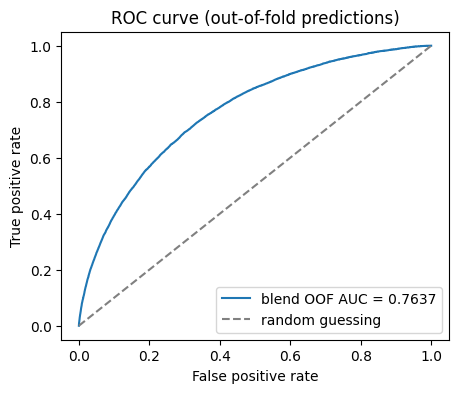

In [ ]:
fpr, tpr, _ = roc_curve(y, blend_oof)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"blend OOF AUC = {roc_auc_score(y, blend_oof):.4f}")
plt.plot([0, 1], [0, 1], "--", color="grey", label="random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.legend()
plt.title("ROC curve (out-of-fold predictions)")
plt.show()

**Findings**:<br>
* Tuning the hyperparameters improved a single LightGBM model (0.761 to 0.763)
* Blending three different models improved it a little more (about 0.764)
* We use the equal-weight blend as the final model

### **[Next Steps]**
> + **What we tried that did not help** (all judged by the same OOF AUC): more features alone; class weights for the imbalance (slightly worse); removing the least important features (no gain); adding a logistic regression with splines to the blend (worse at every weight). Reporting such results is part of good experimentation.
> + Tune CatBoost (`depth`, `l2_leaf_reg`) the way we tuned LightGBM.
> + Add more seeds: it is cheap and gives a small, reliable gain.
> + Beware of tuning to the public leaderboard: trust the OOF AUC, and make sure your **last** submission is the one you trust most.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#).

## 6.Creating Prediction Results

Finally, let's make a prediction for the test data, and prepare a CSV file to submit.

### 6.1 Predicting on the test data
The final prediction is the average of the three models' test predictions. Remember that each test prediction is itself the average of all the cross-validation models of that type (15 + 5 + 10 = 30 models). **The test data was only used to predict, never to train**: the test file has no `TARGET`.

We also put the predictions in the same row order as `sample_submission.csv`, using the customer IDs.

In [ ]:
# Make predictions for the test data: equal-weight average of the three models
blend_test = (lgbm_test + cat_test + lgbm_big_test) / 3

# Put the predictions in the order of sample_submission.csv (matched by customer ID)
pred = pd.Series(blend_test, index=test_ids).loc[sample_sub["SK_ID_CURR"]].values
print("number of predictions:", len(pred))

number of predictions: 61500


### 6.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [ ]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.031070
1,171203,0.190866
2,171204,0.153492
3,171205,0.108430
4,171206,0.181100
...,...,...
61495,232697,0.174562
61496,232698,0.032945
61497,232699,0.055694
61498,232700,0.187578


In [ ]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

### 6.3 Checking the submission file
A file in the wrong format receives a score of -1, so let's check it before uploading.

In [ ]:
check = pd.read_csv(output_file)
print("shape:", check.shape, "| columns:", list(check.columns))
print("missing predictions:", check["TARGET"].isna().sum())
print(f"predictions between {check['TARGET'].min():.4f} and {check['TARGET'].max():.4f}")
assert list(check.columns) == ["SK_ID_CURR", "TARGET"]
assert check["TARGET"].between(0, 1).all()
assert (check["SK_ID_CURR"].values == pd.read_csv(sample_sub_file)["SK_ID_CURR"].values).all()
print("The file looks correct.")

shape: (61500, 2) | columns: ['SK_ID_CURR', 'TARGET']
missing predictions: 0
predictions between 0.0025 and 0.7697
The file looks correct.


That's all for the improved tutorial of Home Credit Default Risk competition! Submit your CSV file to Omnicampus to see the result.

**Summary of the steps**
1. Understand the data (missing values, placeholder codes, outliers, the strong `EXT_SOURCE_*`).
2. Clean it: placeholder codes become missing values; missing values are kept.
3. Create features: ratios and summaries (42 features), and a bigger version (112 features) for diversity.
4. Choose a fair evaluation: stratified 5-fold cross-validation, OOF AUC, several seeds.
5. Tune the hyperparameters (Optuna) and train LightGBM and CatBoost.
6. Average the three models.

An AUC close to 1 is not possible with this data, because a customer's future is not in the table. The original 2018 Kaggle competition reached about 0.80 with seven extra tables that we do not have. Remember that the public leaderboard shows only part of the test data, so the final ranking can move a little.

### 6.4 Saving this notebook as a ZIP file [REQUIREMENT IF AIMING FOR HONORS/OUTSTANDING STUDENTS]
This section compresses the notebook file into a ZIP file and saves it to your working directory.
Make sure to save the notebook (Ctrl+S or Cmd+S) before running this cell to include the latest changes.

If you are aiming to become **Honors or Outstanding Student**, you need to submit the ZIP file as well on Omnicampus. The notebook reproduces the CSV because all random seeds are fixed and no external data is used.

In [ ]:
import zipfile

# Define the file names
notebook_filename = "tutorial.ipynb" # Enter the name of this notebook
zip_filename = "tutorial.zip"

# Define the full paths using current_dir
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename

# Check if the notebook file exists and create the ZIP file
if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        # Add the notebook to the ZIP file (arcname avoids including the full folder structure)
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}' in {current_dir}.")
    print("Please check if the notebook name and the current directory are correct.")

Successfully created: /content/drive/MyDrive/Competition/tutorial.zip
